In [1]:
import numpy as np
import pandas as pd
import sunpy
import sunpy.map
from scipy import signal
import copy
from numpy.linalg import solve
from glob import glob
from datetime import datetime
from scipy.linalg import lstsq
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.path import Path

%matplotlib widget

In [2]:
# Defining the paths where the fits are
path_Br = glob('E:/Research/Data/SDO/HMI/SHARP/AR3664/*00_TAI.Br.fits')

# Building the cubes using Sunpy
cube_Br = sunpy.map.Map(path_Br, sequence=True)

# Creating empty lists to receive the datacubes
data_cube_Br = []
meta_cube_Br = []

for i in range(0, len(cube_Br)):
    data_cube_Br.append(cube_Br[i].data)
    meta_cube_Br.append(cube_Br[i].meta)

# Getting meta infomation    
meta = meta_cube_Br[0]

See https://docs.sunpy.org/en/stable/code_ref/map.html#fixing-map-metadata for how to fix metadata before loading it with sunpy.map.Map.
See https://fits.gsfc.nasa.gov/fits_standard.html forthe FITS unit standards. [sunpy.map.mapbase]


In [3]:
# Reshaping sothat the frames stack in the third axis
data_cube_Br = np.transpose(np.array(data_cube_Br), (2, 1, 0)) # [G]

# Converting magnetic field from spherical coordinate to local Cartesian coordinate
data_cube_Bz = data_cube_Br

# Rotating and fliping 3D array for plotting
data_cube_Bz_rot = np.rot90(data_cube_Bz, axes=(0,1))
data_cube_Bz_flp = np.flip(data_cube_Bz_rot, axis=0)

Bz = data_cube_Bz_flp

In [4]:
# Defining grid for reconstruction, [km] as length unit, [s] as time uint
Rs = 6.9634e5 # solar radia, [km]
dtheta, dphi = 0.03, 0.03 # [deg.]
dx = np.deg2rad(dtheta) * Rs
dy = np.deg2rad(dphi) * Rs
x = range(0, meta['naxis1']) * dx
y = range(0, meta['naxis2']) * dy

print('dx[km]: ', dx)
print('dy[km]: ', dy)
print('shape: ', Bz.shape)

dx[km]:  364.6027714001194
dy[km]:  364.6027714001194
shape:  (513, 1202, 1109)


In [5]:
def mark_parallelogram(ax, coord1, coord2, coord3, coord4, color='k'):
    
    coord1 = np.array(coord1)
    coord2 = np.array(coord2)
    coord3 = np.array(coord3)
    coord4 = np.array(coord4)
    
    vertices = np.array([coord1, coord2, coord3, coord4])
    
    parallelogram = Polygon(vertices, fill=False, edgecolor=color, linewidth=2)
    ax.add_patch(parallelogram)
    
    return vertices

def extract_parallelogram(Bz, ind_t, vertices):
    
    x_min = max(0, int(np.floor(np.min(vertices[:, 0]))))
    x_max = min(meta['naxis1'], int(np.ceil(np.max(vertices[:, 0]))))
    y_min = max(0, int(np.floor(np.min(vertices[:, 1]))))
    y_max = min(meta['naxis2'], int(np.ceil(np.max(vertices[:, 1]))))
    
    y, x = np.indices((y_max - y_min, x_max - x_min))
    points = np.stack([x.ravel() + x_min, y.ravel() + y_min], axis=1)
    
    path = Path(vertices)
    mask = path.contains_points(points).reshape(y_max - y_min, x_max - x_min)
    
    Bz_mask = Bz[y_min:y_max, x_min:x_max, ind_t].copy()
    Bz_mask[~mask] = np.nan
    
    return Bz_mask

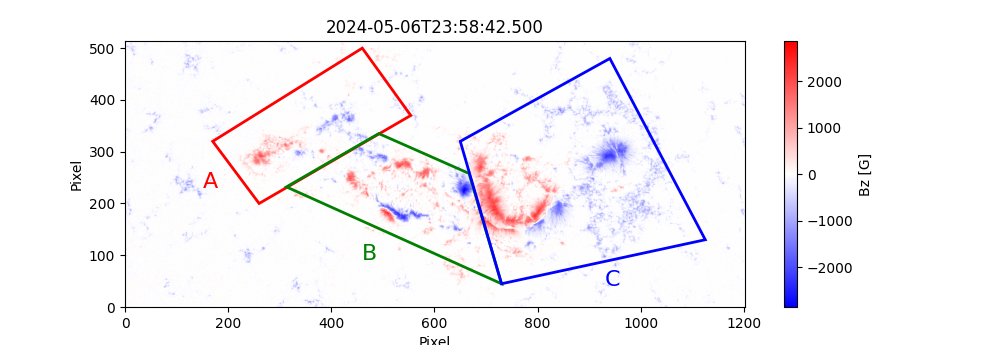

In [6]:
fig = plt.figure(figsize=(10,3.45))
i_plot = 510

# Plotting magnetic field
ax = plt.subplot(111)
Bz_abs_max = np.max(np.abs(Bz[:,:,i_plot]))
plt.pcolormesh(Bz[:,:,i_plot], cmap='bwr', vmin=-Bz_abs_max, vmax=Bz_abs_max)
cb = plt.colorbar()
cb.set_label('Bz [G]')
plt.xlabel('Pixel')
plt.ylabel('Pixel')

# Plotting subregion of parallelogram
vertices1 = mark_parallelogram(ax, [260,200], [554,370], [460,500], [170,320],'r')
# vertices1 = mark_parallelogram(ax, [260,200], [554,370], [460,500], [170,320],'r')
Bz_subplot1 = extract_parallelogram(Bz, i_plot, vertices1)
vertices2 = mark_parallelogram(ax, [492,335], [667,258], [730, 45], [313,232],'g')
# vertices2 = mark_parallelogram(ax, [552,370], [650,320], [730, 45], [260,200],'g')
Bz_subplot2 = extract_parallelogram(Bz, i_plot, vertices2)
vertices3 = mark_parallelogram(ax, [650,320], [730, 45], [1125,130], [940,480],'b')
# vertices3 = mark_parallelogram(ax, [650,320], [730, 45], [1125,130], [940,480],'b')
Bz_subplot3 = extract_parallelogram(Bz, i_plot, vertices3)

# Marking region number
plt.text(150, 230, 'A', color='r', fontsize=16)
plt.text(460,  90, 'B', color='g', fontsize=16)
plt.text(930,  40, 'C', color='b', fontsize=16)

# Figure settings
plt.xlim([0, meta['naxis1']])
plt.ylim([0, meta['naxis2']])
plt.title(meta_cube_Br[i_plot]['date-obs'])
plt.axis('equal')

plt.show()

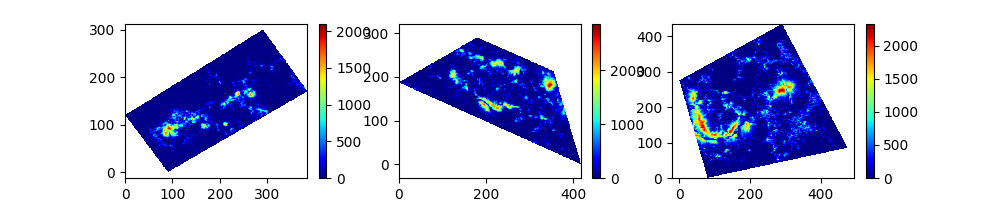

In [7]:
fig = plt.figure(figsize=(10,2))

plt.subplot(131)
plt.pcolormesh(np.abs(Bz_subplot1), cmap='jet')
plt.colorbar()
plt.axis('equal')

plt.subplot(132)
plt.pcolormesh(np.abs(Bz_subplot2), cmap='jet')
plt.colorbar()
plt.axis('equal')

plt.subplot(133)
plt.pcolormesh(np.abs(Bz_subplot3), cmap='jet')
plt.colorbar()
plt.axis('equal')

# plt.tight_layout()
plt.show()

In [8]:
# Calculating magnetic flux
Phi = np.zeros([len(cube_Br), 1])
Phi_sub1 = np.zeros_like(Phi)
Phi_sub2 = np.zeros_like(Phi)
Phi_sub3 = np.zeros_like(Phi)
for i in range(0, len(cube_Br)):
    Bz_sub = Bz[:,:,i].copy()
    Bz_sub1 = extract_parallelogram(Bz, i, vertices1)
    Bz_sub2 = extract_parallelogram(Bz, i, vertices2)
    Bz_sub3 = extract_parallelogram(Bz, i, vertices3)
    
    Bz_sub[np.abs(Bz_sub)<200] = np.nan
    Bz_sub1[np.abs(Bz_sub1)<200] = np.nan
    Bz_sub2[np.abs(Bz_sub2)<200] = np.nan
    Bz_sub3[np.abs(Bz_sub3)<200] = np.nan
    
    Phi[i] = np.nansum(np.abs(Bz_sub))
    Phi_sub1[i] = np.nansum(np.abs(Bz_sub1))
    Phi_sub2[i] = np.nansum(np.abs(Bz_sub2))
    Phi_sub3[i] = np.nansum(np.abs(Bz_sub3))

Phi = Phi * dx * dy * 1e-3 # [Wb]
Phi_sub1 = Phi_sub1 * dx * dy * 1e-3 # [Wb]
Phi_sub2 = Phi_sub2 * dx * dy * 1e-3 # [Wb]
Phi_sub3 = Phi_sub3 * dx * dy * 1e-3 # [Wb]
Phi_sub = Phi_sub1 + Phi_sub2 + Phi_sub3 # [Wb]

In [9]:
# ## Saving Unsigned Flux data
# Phi_123 = {
#     'Phi_sub1': Phi_sub1.flatten(),
#     'Phi_sub2': Phi_sub2.flatten(),
#     'Phi_sub3': Phi_sub3.flatten()
# }

# df = pd.DataFrame(Phi_123)

# df.to_csv('phi_123.csv', index=False)

# print('Saved to phi_123.csv')

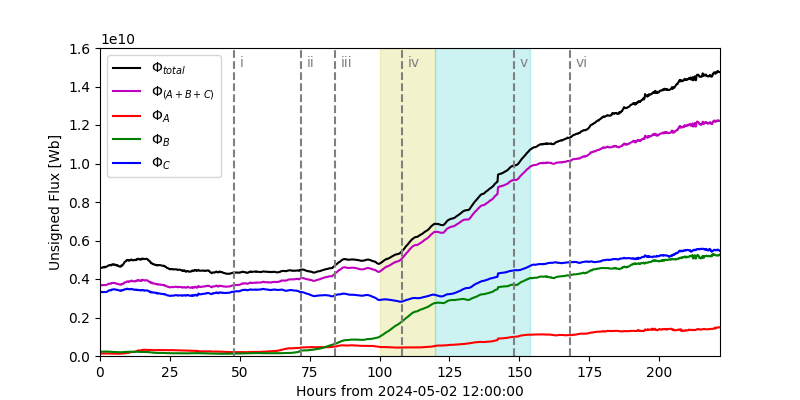

In [10]:
plt.figure(figsize=(8,4))
t_hr = np.arange(0, Phi.shape[0]) / 5
plt.plot(t_hr, Phi, 'k', label=r'$\Phi_{total}$')
plt.plot(t_hr, Phi_sub, 'm', label=r'$\Phi_{(A+B+C)}$')
plt.plot(t_hr, Phi_sub1, 'r', label=r'$\Phi_A$')
plt.plot(t_hr, Phi_sub2, 'g', label=r'$\Phi_B$')
plt.plot(t_hr, Phi_sub3, 'b', label=r'$\Phi_C$')
plt.axvspan(100, 120, color='y', alpha=0.2)
plt.axvspan(120, 154, color='c', alpha=0.2)
plt.vlines(x=48, ymin=0, ymax=1.6e10, colors='gray', linestyles='dashed')
plt.text(50, 1.5e10, 'i', color='gray', fontsize=10)
plt.vlines(x=72, ymin=0, ymax=1.6e10, colors='gray', linestyles='dashed')
plt.text(74, 1.5e10, 'ii', color='gray', fontsize=10)
plt.vlines(x=84, ymin=0, ymax=1.6e10, colors='gray', linestyles='dashed')
plt.text(86, 1.5e10, 'iii', color='gray', fontsize=10)
plt.vlines(x=108, ymin=0, ymax=1.6e10, colors='gray', linestyles='dashed')
plt.text(110, 1.5e10, 'iv', color='gray', fontsize=10)
plt.vlines(x=148, ymin=0, ymax=1.6e10, colors='gray', linestyles='dashed')
plt.text(150, 1.5e10, 'v', color='gray', fontsize=10)
plt.vlines(x=168, ymin=0, ymax=1.6e10, colors='gray', linestyles='dashed')
plt.text(170, 1.5e10, 'vi', color='gray', fontsize=10)
plt.xlabel('Hours from 2024-05-02 12:00:00')
plt.ylabel('Unsigned Flux [Wb]')
plt.xlim([0, Phi.shape[0]/5])
plt.ylim([0, 1.6e10])
# plt.yscale('log')
plt.legend()
plt.show()

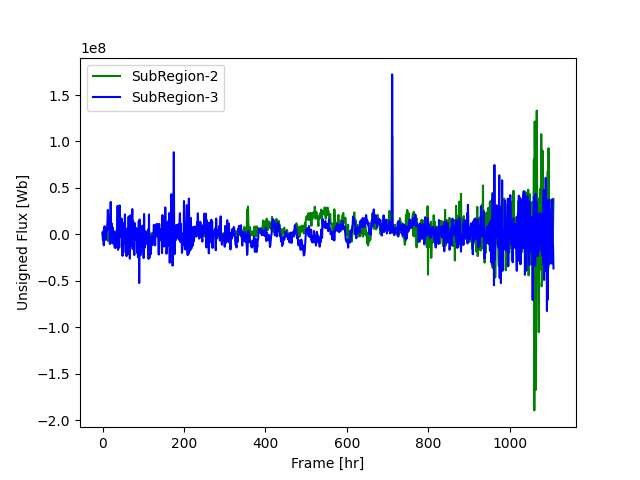

In [11]:
plt.figure()
# plt.plot(np.diff(Phi, axis=0), 'k', label='TOTAL')
# plt.plot(np.diff(Phi_sub, axis=0), 'm', label='Subregions')
# plt.plot(np.diff(Phi_sub1, axis=0), 'r', label='SubRegion-1')
plt.plot(np.diff(Phi_sub2, axis=0), 'g', label='SubRegion-2')
plt.plot(np.diff(Phi_sub3, axis=0), 'b', label='SubRegion-3')
plt.xlabel('Frame [hr]')
plt.ylabel('Unsigned Flux [Wb]')
# plt.yscale('log')
plt.legend()
plt.show()

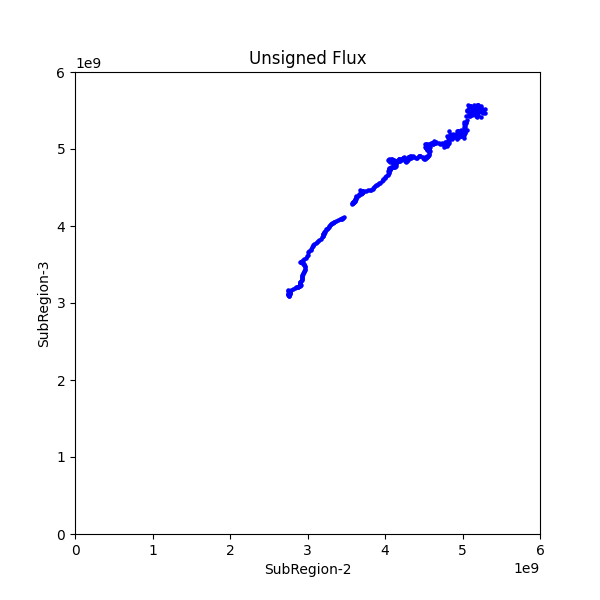

In [12]:
plt.figure(figsize=(6,6))
plt.scatter(Phi_sub2[600:], Phi_sub3[600:], s=5, c='b')
# plt.plot([0, 6e9], [0, 6e9], 'k')
plt.xlim([0, 6e9])
plt.ylim([0, 6e9])
plt.xlabel('SubRegion-2')
plt.ylabel('SubRegion-3')
plt.title('Unsigned Flux')
plt.show()